# Decision Trees for Classification
### A walkthrough of `DecisionTree.py`

A **decision tree classifier** predicts a class label by asking a short sequence of yes/no questions about the input, each of the form *"is feature $j$ at most $\tau$?"*. The questions are learned from data by a greedy, recursive procedure: find the single question that best separates the classes, split the data by its answer, and repeat inside each half.

This notebook teaches that procedure from first principles and runs the implementation in this folder (`DecisionTree.py`) at every step. By the end you should be able to:

1. state the classification problem a tree solves and why a tree's *piecewise-constant, axis-aligned* model is a natural fit for it;
2. derive the Gini and entropy impurity measures, the information-gain criterion, and why that gain can never be negative;
3. explain exactly how `DecisionTreeClassifier` searches for splits, when it stops, how it labels leaves, and how it predicts, line by line;
4. work a complete example by hand and confirm every number against the code;
5. predict how `max_depth` and `min_samp_split` trade bias against variance, and what the algorithm costs to run.

**How to read it.** Every core topic follows the same five-step pattern: **Concept** (intuition) → **Math** (step-by-step derivation) → **Illustration** (a small, clearly labelled teaching snippet) → **Your implementation** (a call into `DecisionTree.py`) → **Check** (an `assert` that the code matches the formula). Two kinds of note appear along the way. Cells titled *🔧 Fixed in the code* record bugs that were found while this notebook was being written and have since been corrected in `DecisionTree.py`. Each one describes the original behaviour, the fix, and a cell that demonstrates the corrected behaviour. Cells titled *⚠️ Note on the implementation* point out design choices that differ from production libraries and are still present in the code.

**Where this fits.** This is the first notebook in a series. The same tree idea is reused, with modifications, by every other folder in this repo:
[Regression trees](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) ·
[Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) ·
[AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) ·
[Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) ·
[Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) ·
[XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb).

### Notation (shared by all notebooks in this series)

| Symbol | Meaning |
|---|---|
| $X \in \mathbb{R}^{n\times m}$, $x_i$ | data matrix with $n$ samples (rows) and $m$ features; $x_i$ is row $i$ |
| $x_{ij}$ | value of feature $j$ for sample $i$. Features are indexed $j = 0,\dots,m-1$ to match the code, which prints them as `X_0`, `X_1`, … |
| $y_i \in \{0,\dots,K-1\}$ | class label of sample $i$; $K$ is the number of classes |
| $S$ | the set of training samples that reach a node; $\lvert S\rvert$ is its size |
| $(j, \tau)$ | a split: send $x$ left if $x_j \le \tau$, right otherwise |
| $S_L, S_R$ | the left and right children of $S$ under a split |
| $p_k(S)$ | fraction of the samples in $S$ that belong to class $k$ |
| $I(S)$ | an impurity measure (Gini $G$ or entropy $H$) |
| $\Delta(S; j, \tau)$ | information gain (impurity decrease) of a split |
| $v_\ell$, $R_\ell$ | the value predicted by leaf $\ell$ and the region of input space it covers |
| $T$, $\eta$, $F_t$ | number of trees, learning rate, and the ensemble after $t$ trees (used in the ensemble notebooks) |

## 1. Setup

The first cell imports NumPy and matplotlib, fixes the random seed, sets the plot style used across the whole series, and puts this folder on `sys.path` so that `import DecisionTree` loads **your** module. The second cell defines small teaching helpers (data generators and plotting); they are illustration code and never re-implement the tree.

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "DecisionTree.py").exists(), "Open/run this notebook from inside the DecisionTree/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from DecisionTree.py, never copied into this notebook
import DecisionTree as dt_mod
from DecisionTree import DecisionTreeClassifier, Node

print("module:", Path(dt_mod.__file__).name)
print("DecisionTreeClassifier methods:", [k for k in vars(DecisionTreeClassifier) if not k.startswith("__")])

module: DecisionTree.py
DecisionTreeClassifier methods: ['build_tree', 'get_best_split', 'information_gain', 'split', 'entropy', 'gini_index', 'calculate_leaf_value', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem: supervised classification

We observe $n$ labelled examples $\{(x_i, y_i)\}_{i=1}^{n}$, with feature vectors $x_i \in \mathbb{R}^m$ and labels $y_i \in \{0, \dots, K-1\}$. We assume they are independent draws from some unknown joint distribution $P(x, y)$. The goal is a rule $\hat f: \mathbb{R}^m \to \{0,\dots,K-1\}$ that labels **new** inputs correctly as often as possible, that is, a rule with small *misclassification risk*

$$
R(\hat f) \;=\; P\big(\hat f(x) \ne y\big).
$$

If we knew the class probabilities $P(y = k \mid x)$, the best possible rule would be the **Bayes classifier** $f^*(x) = \arg\max_k P(y=k\mid x)$. It is optimal because, for each fixed $x$, predicting class $k$ is wrong with probability $1 - P(y=k \mid x)$, and choosing the largest $P(y=k\mid x)$ makes that error as small as possible. Every practical classifier is an attempt to estimate $P(y = k \mid x)$, or at least its argmax, from finite data.

**What makes this hard.** The relationship between $x$ and $y$ can be highly non-linear, and the label can depend on *interactions* between features, not on any single feature by itself. Labels can also be noisy, in which case even $f^*$ makes mistakes. Finally, with finite $n$ we can always fit the training data perfectly by memorising it, and that memorised rule generalises badly. A good method must be flexible enough to capture non-linear interactions and still be controllable enough to avoid fitting noise.

The data set below is a deliberately hard toy example: the noisy **XOR** problem. Class 1 occupies the second and fourth quadrants of the square $[-1,1]^2$, and 10% of the labels are flipped at random. Each feature on its own carries essentially no information about the class; only the combination of the two does.

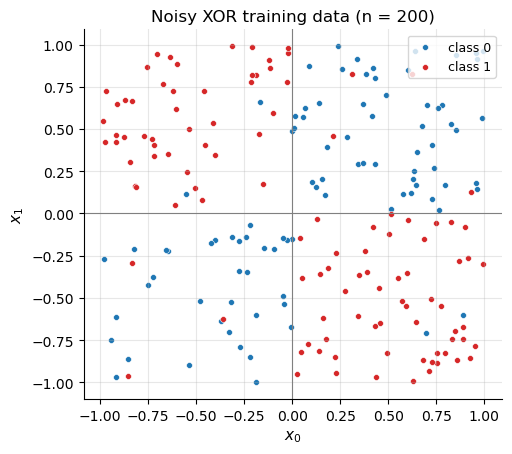

class balance: 0.55 of the training points are class 1


In [4]:
# Motivating data set: noisy XOR (class 1 when x0*x1 < 0, then 10% of labels flipped)
X_xor, y_xor = make_xor(200, noise=0.10)
X_xor_test, y_xor_test = make_xor(2000, noise=0.10)      # large held-out set for estimating the risk

fig, ax = plt.subplots(figsize=(5.4, 4.8))
for k in (0, 1):
    m = y_xor == k
    ax.scatter(X_xor[m, 0], X_xor[m, 1], s=18, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set(title="Noisy XOR training data (n = 200)", xlabel="$x_0$", ylabel="$x_1$")
ax.legend(loc="upper right", frameon=True); plt.show()
print(f"class balance: {np.mean(y_xor == 1):.2f} of the training points are class 1")

Notice that projecting the points onto either axis would show both colours spread evenly along it, so neither feature alone tells you the class. The Bayes classifier here is "class 1 if $x_0 x_1 < 0$". Because 10% of labels are flipped, even that perfect rule is only about **90%** accurate. That 90% is the ceiling every model in this notebook is measured against.

How badly does a *linear* classifier fail? The illustration below tries 20,000 random straight lines and keeps the best training accuracy, allowing either side of each line to be called class 1.

In [5]:
# Illustration only — not the repo implementation.
# Best training accuracy achievable by any of 20,000 random straight lines w·x + b = 0
W = rng.normal(size=(20_000, 2))
b = rng.uniform(-1, 1, size=20_000)
side = (X_xor @ W.T + b) > 0                                   # (n, lines): which side each point falls on
acc = (side == y_xor[:, None]).mean(axis=0)
acc = np.maximum(acc, 1 - acc)                                 # either side may be labelled class 1
print(f"best of 20,000 linear rules: training accuracy = {acc.max():.3f}")
print(f"always predict the majority class:              {max(y_xor.mean(), 1 - y_xor.mean()):.3f}")

best of 20,000 linear rules: training accuracy = 0.695
always predict the majority class:              0.545


Even the best line does far worse than the 90% ceiling. A single line can at best cut off one quadrant and label it correctly, and it must get the opposite quadrant of the same class wrong. To do better, we need a model that can carve the plane into **several** regions and give each its own label.

## 3. Why a decision tree fits this problem

A decision tree partitions the input space into axis-aligned boxes $R_1, \dots, R_L$, one per leaf, and predicts a single class in each box:

$$
\hat f(x) \;=\; \sum_{\ell=1}^{L} v_\ell \,\mathbb{1}[x \in R_\ell], \qquad v_\ell \in \{0, \dots, K-1\}. \tag{0}
$$

It builds the partition recursively. The root asks one question $x_j \le \tau$ and splits the space into two half-spaces. Each child asks its own question inside its half, and so on. Because a child's question is asked **only** for the points that reached it, the tree naturally represents interactions. For XOR, "is $x_0 \le 0$?" followed by "is $x_1 \le 0$?" in each child carves out exactly the four quadrants.

**Strengths**
- *Non-parametric and flexible.* There is no assumption that classes are linearly separable or Gaussian; with enough leaves a tree can approximate any decision boundary built from axis-aligned pieces.
- *Interactions for free.* Nested questions model "feature A matters only when feature B is large".
- *No feature scaling required.* A split only compares a feature with a threshold, so any strictly increasing transformation of a feature (log, exp, standardisation) gives the same partition of the training data and the same predictions. We check this below with your implementation.
- *Interpretable.* A shallow tree is a readable flowchart (`print_tree` prints it).

**Assumptions and weaknesses**
- Boundaries are built from **axis-aligned** steps, so a diagonal boundary needs many small steps.
- The tree is grown **greedily**: each split is the best one available *right now*, with no look-ahead. On XOR this is a real handicap, as Section 7.3 shows.
- A deep tree has **high variance**: small changes to the training data can change the top split and therefore the entire tree. This instability is why ensembles exist. [Random Forests](../RandomForest/RandomForest_Walkthrough.ipynb) average many decorrelated deep trees to *reduce variance*. Boosting methods ([AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb), [Gradient Boosting](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb), [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)) add up many shallow trees to *reduce bias*.

Here is the end product on the XOR data, as a preview. Everything in it is explained in the sections that follow.

tree depth = 3, leaves = 8, train accuracy = 0.940, test accuracy = 0.870

X_1 <= -0.23264489147623313 ? 0.01890665465662178
    left:X_0 <= -0.00685661240229396 ? 0.3101240044401864
        left:X_0 <= -0.36063672743467 ? 0.026442307692307737
                left:0.0
                right:0.0
        right:X_0 <= 0.6826345592247665 ? 0.005337018417478551
                left:1.0
                right:1.0
    right:X_0 <= -0.02230090633307147 ? 0.14189747099636607
        left:X_1 <= -0.06643296031147305 ? 0.30802651616948873
                left:0.0
                right:1.0
        right:X_1 <= -0.005154609024762058 ? 0.2076536496951721
                left:1.0
                right:0.0


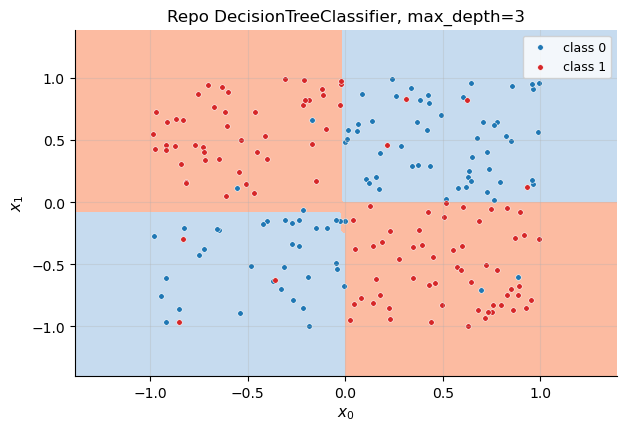

In [6]:
# Preview: the repo's tree on the XOR data
clf_preview = DecisionTreeClassifier(min_samp_split=2, max_depth=3)
clf_preview.fit(X_xor, y_xor.reshape(-1, 1))            # y as a column vector (n, 1); a 1-D vector also works
train_acc = np.mean(np.array(clf_preview.predict(X_xor)) == y_xor)
test_acc = np.mean(np.array(clf_preview.predict(X_xor_test)) == y_xor_test)
print(f"tree depth = {tree_depth(clf_preview.root)}, leaves = {count_leaves(clf_preview.root)}, "
      f"train accuracy = {train_acc:.3f}, test accuracy = {test_acc:.3f}\n")
clf_preview.print_tree()
plot_decision_regions(clf_preview.predict, X_xor, y_xor, title="Repo DecisionTreeClassifier, max_depth=3")
plt.show()

`print_tree` prints each decision node as `X_j <= τ ? gain`, followed by its `left:` (condition true) and `right:` (condition false) subtrees, and prints leaves as their class label. The shaded regions are the boxes $R_\ell$ of Eq. (0). Using only axis-aligned questions, the tree has approximately recovered the four quadrants, and its test accuracy is within a few points of the 90% ceiling. One detail is worth noticing now: the root question is $x_1 \le -0.23$ with a tiny gain, not the "natural" $x_0 \le 0$. Section 7.3 explains why a greedy learner struggles to find the right first split on XOR.

**Check: invariance to monotone feature transforms.** Claim: if each feature is passed through a *strictly increasing* function $\phi_j$, the fitted tree makes identical predictions (on correspondingly transformed inputs). Reason: a threshold split $x_j \le \tau$ on the original data puts exactly the same samples on each side as the split $\phi_j(x_j) \le \phi_j(\tau)$ on the transformed data, because $\phi_j$ preserves order. Every candidate therefore produces the same partition and the same impurities, so the same split wins at every node, and a new point is routed the same way.

In [7]:
# Check: strictly increasing transforms of the features leave predictions unchanged
Xm, ym = make_moons(120, noise=0.25)
Xtr, Xte, ytr, yte = train_test_split_np(Xm, ym, test_frac=0.5)
phi = lambda Z: np.c_[np.exp(Z[:, 0]), Z[:, 1] ** 3]          # exp and cube are strictly increasing

tree_raw = DecisionTreeClassifier(min_samp_split=2, max_depth=3); tree_raw.fit(Xtr, ytr.reshape(-1, 1))
tree_phi = DecisionTreeClassifier(min_samp_split=2, max_depth=3); tree_phi.fit(phi(Xtr), ytr.reshape(-1, 1))
pred_raw, pred_phi = np.array(tree_raw.predict(Xte)), np.array(tree_phi.predict(phi(Xte)))
assert np.array_equal(pred_raw, pred_phi)
print(f"✓ identical predictions on all {len(Xte)} test points after transforming the features")

✓ identical predictions on all 60 test points after transforming the features


This confirms why trees need no feature scaling: only the **order** of each feature's values matters. Methods based on distances (k-NN, SVMs) or on gradient steps (neural networks) do not have this property.

## 4. Core concepts, theory and math

Growing a tree requires answering four questions, which the subsections take in turn:

1. **How impure is a node?** (impurity measures, §4.1)
2. **How good is a split?** (information gain, §4.2)
3. **Which split is best?** (exhaustive search over candidate thresholds, §4.3)
4. **When do we stop, and what does a leaf predict?** (stopping rules and leaf values, §4.4)

followed by how a finished tree makes a prediction (§4.5).

### 4.1 Impurity: measuring how mixed a node is

**Concept.** A node is *pure* if all its training samples have the same class; then its prediction is certainly right on the training data. It is maximally *impure* if all classes are equally represented. An impurity function $I(S)$ summarises the class proportions

$$
p_k(S) \;=\; \frac{1}{|S|}\sum_{i \in S} \mathbb{1}[y_i = k], \qquad k = 0,\dots,K-1,
$$

into one number that is $0$ for a pure node and largest for a uniform mix. The implementation provides two such functions.

**Math: Gini impurity.**

$$
G(S) \;=\; \sum_{k=0}^{K-1} p_k (1-p_k) \;=\; \sum_k p_k - \sum_k p_k^2 \;=\; 1 - \sum_{k=0}^{K-1} p_k^2 . \tag{1}
$$

The second equality expands the product. The third uses $\sum_k p_k = 1$, since the proportions of all classes add up to the whole node.

*Interpretation.* Draw two samples from the node independently, with replacement. The probability that both have class $k$ is $p_k^2$, so the probability that they have the *same* class is $\sum_k p_k^2$, and the probability that they *disagree* is $1-\sum_k p_k^2 = G(S)$. Equivalently, $G$ is the error rate of a "random guesser" that labels a sample from the node with a class drawn from the node's own proportions: it guesses $k$ with probability $p_k$ and is then wrong with probability $1-p_k$, which gives $\sum_k p_k(1-p_k)$.

*Range.* $G \ge 0$, with equality iff some $p_k = 1$ (a pure node). To find the maximum, maximise $1 - \sum_k p_k^2$ subject to $\sum_k p_k = 1$. The Lagrangian $\mathcal{L} = 1 - \sum_k p_k^2 + \mu(\sum_k p_k - 1)$ has $\partial \mathcal{L}/\partial p_k = -2p_k + \mu = 0$, so all $p_k$ are equal, $p_k = 1/K$. That gives $G_{\max} = 1 - K\cdot\frac{1}{K^2} = 1 - \frac{1}{K}$ (for example $0.5$ when $K = 2$).

**Math: entropy.**

$$
H(S) \;=\; -\sum_{k=0}^{K-1} p_k \log_2 p_k, \qquad \text{with the convention } 0 \log_2 0 = 0. \tag{2}
$$

$H$ is the expected number of bits needed to encode the class of a random sample from the node. The same Lagrangian argument ($\partial/\partial p_k$ gives $-\log_2 p_k - 1/\ln 2 + \mu = 0$, so all $p_k$ are equal) shows the maximum is $H_{\max} = \log_2 K$ at the uniform distribution. The minimum is $0$ for a pure node.

*Concavity.* Both measures are **strictly concave** functions of the proportion vector $p = (p_0,\dots,p_{K-1})$. For Gini, the Hessian of $-\sum_k p_k^2$ is $-2\,\mathrm{I}$, which is negative definite. For entropy, $\partial^2/\partial p_k^2\,(-p_k\log_2 p_k) = -1/(p_k \ln 2) < 0$ and all cross-derivatives are zero. Concavity is exactly what makes information gain non-negative (§4.2).

**Illustration.** For $K=2$, write $p = p_1$. Then $G = 2p(1-p)$ and $H = -p\log_2 p - (1-p)\log_2(1-p)$. The plot also shows the misclassification rate $1-\max_k p_k$ for comparison.

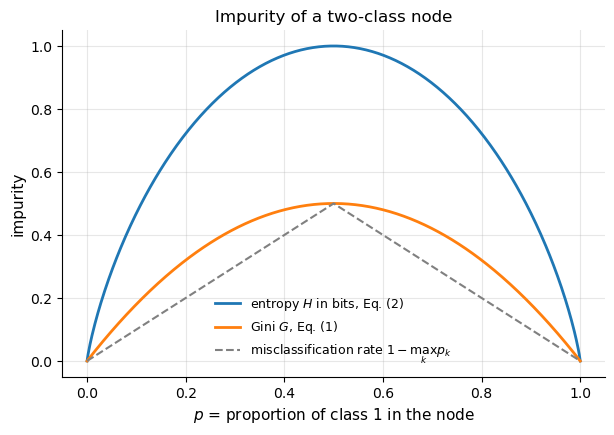

In [8]:
# Illustration only — the impurity measures for K = 2 as functions of p = P(class 1)
p = np.linspace(0, 1, 501)
with np.errstate(divide="ignore", invalid="ignore"):
    H = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(p < 1, (1 - p) * np.log2(1 - p), 0.0))
G = 1 - p**2 - (1 - p)**2
E = 1 - np.maximum(p, 1 - p)

fig, ax = plt.subplots()
ax.plot(p, H, lw=2, label="entropy $H$ in bits, Eq. (2)")
ax.plot(p, G, lw=2, label="Gini $G$, Eq. (1)")
ax.plot(p, E, "--", lw=1.5, color="gray", label="misclassification rate $1-\\max_k p_k$")
ax.set(title="Impurity of a two-class node", xlabel="$p$ = proportion of class 1 in the node", ylabel="impurity")
ax.legend(); plt.show()

All three measures are $0$ at $p\in\{0,1\}$ (pure nodes) and peak at $p = 0.5$: Gini at $0.5$, entropy at $1$ bit. Gini and entropy are smooth and strictly concave, while the misclassification rate is piecewise linear. That difference matters for split selection. Because the misclassification rate is linear on each side of $0.5$, a split whose children both stay on the same side of $0.5$ gets *zero* gain from it, even if one child becomes much purer. The curved measures reward such progress. This is why tree learners use Gini or entropy rather than the error rate itself.

A quick Monte Carlo experiment confirms the probabilistic reading of Eq. (1).

In [9]:
# Illustration only — Gini as "probability that two labels drawn at random from the node disagree"
labels = np.array([0, 0, 0, 1, 1, 2, 2, 2, 2, 2], dtype=float)     # a node with K = 3 classes
draws = rng.integers(0, len(labels), size=(200_000, 2))            # two independent draws, with replacement
mc = np.mean(labels[draws[:, 0]] != labels[draws[:, 1]])
p_k = np.bincount(labels.astype(int)) / len(labels)
print("class proportions p_k:", p_k)
print(f"Monte-Carlo P(two draws disagree) = {mc:.4f}   vs   1 - sum_k p_k^2 = {1 - np.sum(p_k**2):.4f}")

class proportions p_k: [0.3 0.2 0.5]
Monte-Carlo P(two draws disagree) = 0.6206   vs   1 - sum_k p_k^2 = 0.6200


**Your implementation.** `DecisionTreeClassifier.gini_index(y)` and `DecisionTreeClassifier.entropy(y)` take the labels of a node and return $G$ and $H$. Neither method depends on the fitted tree, so a fresh instance is enough to call them.

In [10]:
clf = DecisionTreeClassifier()          # fresh instance, used only for its helper methods
for y_node in [labels, np.array([1., 1, 1, 1]), np.array([0., 1, 0, 1]), np.array([0., 1, 2, 3])]:
    print(f"y = {str(y_node):<34} gini_index = {clf.gini_index(y_node):.4f}   entropy = {clf.entropy(y_node):.4f}")

y = [0. 0. 0. 1. 1. 2. 2. 2. 2. 2.]    gini_index = 0.6200   entropy = 1.4855
y = [1. 1. 1. 1.]                      gini_index = 0.0000   entropy = 0.0000
y = [0. 1. 0. 1.]                      gini_index = 0.5000   entropy = 1.0000
y = [0. 1. 2. 3.]                      gini_index = 0.7500   entropy = 2.0000


In [11]:
# Check — independent formula versions of Eqs. (1) and (2) (illustration code, not the repo's)
def gini_formula(y):
    p = np.unique(y, return_counts=True)[1] / len(y)
    return 1 - np.sum(p**2)

def entropy_formula(y):
    p = np.unique(y, return_counts=True)[1] / len(y)
    return -np.sum(p * np.log2(p))

for _ in range(200):
    y_rand = rng.integers(0, 4, size=rng.integers(1, 30)).astype(float)
    assert np.isclose(clf.gini_index(y_rand), gini_formula(y_rand))
    assert np.isclose(clf.entropy(y_rand), entropy_formula(y_rand))
uniform4 = np.array([0., 1, 2, 3])
assert np.isclose(clf.gini_index(uniform4), 1 - 1/4) and np.isclose(clf.entropy(uniform4), np.log2(4))
print("✓ gini_index and entropy agree with Eqs. (1)-(2) on 200 random label vectors")
print("✓ at the uniform distribution with K = 4 they reach the derived maxima 1 - 1/K = 0.75 and log2 K = 2")

✓ gini_index and entropy agree with Eqs. (1)-(2) on 200 random label vectors
✓ at the uniform distribution with K = 4 they reach the derived maxima 1 - 1/K = 0.75 and log2 K = 2


The code's `gini_index` computes $1-\sum_k p_k^2$ exactly as in Eq. (1). Its `entropy` computes Eq. (2) using base-2 logarithms. It only loops over classes that are actually present, so the $0\log 0$ case never arises. Both reach the maxima derived above.

### 4.2 Splits and information gain

**Concept.** A split $(j,\tau)$ sends every sample in $S$ to the left child if $x_{ij}\le\tau$ and to the right child otherwise:

$$
S_L(j,\tau) = \{ i \in S : x_{ij} \le \tau \}, \qquad S_R(j,\tau) = \{ i \in S : x_{ij} > \tau \}.
$$

A good split produces children that are purer than the parent. We measure the improvement as the parent's impurity minus the **size-weighted average** impurity of the children:

$$
\Delta(S; j, \tau) \;=\; I(S) \;-\; \left( \frac{|S_L|}{|S|}\, I(S_L) \;+\; \frac{|S_R|}{|S|}\, I(S_R) \right). \tag{3}
$$

This is called the *information gain* when $I = H$. The code uses the same name for any $I$.

*Why weight by size?* The weighted sum $\frac{|S_L|}{|S|} I(S_L) + \frac{|S_R|}{|S|} I(S_R)$ is the impurity a randomly chosen sample from $S$ experiences *after* the split, because a fraction $|S_L|/|S|$ of samples land in the left child. Without the weights, a split that peels off one sample into a tiny pure child would look as good as one that cleanly separates large groups.

**Math: the gain is never negative.** Let $w_L = |S_L|/|S|$ and $w_R = |S_R|/|S|$, so $w_L + w_R = 1$. Count class $k$ in the parent and children: $n_k(S) = n_k(S_L) + n_k(S_R)$, since every sample goes to exactly one child. Dividing by $|S|$,

$$
p_k(S) \;=\; \frac{n_k(S_L)}{|S|} + \frac{n_k(S_R)}{|S|} \;=\; \frac{|S_L|}{|S|}\frac{n_k(S_L)}{|S_L|} + \frac{|S_R|}{|S|}\frac{n_k(S_R)}{|S_R|} \;=\; w_L\, p_k(S_L) + w_R\, p_k(S_R).
$$

So the parent's proportion vector is a convex combination of the children's. Since $I$ is concave (§4.1), Jensen's inequality gives

$$
I\big(p(S)\big) \;=\; I\big(w_L p(S_L) + w_R p(S_R)\big) \;\ge\; w_L I\big(p(S_L)\big) + w_R I\big(p(S_R)\big) \quad\Longrightarrow\quad \Delta \ge 0 .
$$

Strict concavity means equality holds **only** when $p(S_L) = p(S_R)$, i.e. when the split leaves the class mix unchanged on both sides. Such a split teaches us nothing.

**Illustration.** Eq. (3) by hand for a 10-sample node split into $\{4\times 0, 1\times 1\}$ and $\{5\times 1\}$.

In [12]:
# Illustration only — Eq. (3) computed by hand
y_parent = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1], dtype=float)
y_left, y_right = y_parent[:5], y_parent[5:]                  # left = four 0s and one 1, right = five 1s
wL, wR = len(y_left) / len(y_parent), len(y_right) / len(y_parent)
gP, gL, gR = gini_formula(y_parent), gini_formula(y_left), gini_formula(y_right)
manual = gP - (wL * gL + wR * gR)
print(f"G(S) = {gP:.4f},  G(S_L) = {gL:.4f},  G(S_R) = {gR:.4f}")
print(f"Gini gain = {gP:.4f} - ({wL:.1f}·{gL:.4f} + {wR:.1f}·{gR:.4f}) = {manual:.4f}")

G(S) = 0.4800,  G(S_L) = 0.3200,  G(S_R) = 0.0000
Gini gain = 0.4800 - (0.5·0.3200 + 0.5·0.0000) = 0.3200


**Your implementation.** `information_gain(parent, l_child, r_child, mode)` receives the three label arrays and computes Eq. (3) with `mode='gini'` or (the default) `mode='entropy'`.

In [13]:
g_gini = clf.information_gain(y_parent, y_left, y_right, "gini")
g_ent  = clf.information_gain(y_parent, y_left, y_right, "entropy")
print(f"information_gain(..., 'gini')    = {g_gini:.4f}")
print(f"information_gain(..., 'entropy') = {g_ent:.4f}")

information_gain(..., 'gini')    = 0.3200
information_gain(..., 'entropy') = 0.6100


In [14]:
# Check — Eq. (3) for both impurities, and non-negativity (Jensen) over many random splits
assert np.isclose(g_gini, manual)
ent_manual = entropy_formula(y_parent) - (wL * entropy_formula(y_left) + wR * entropy_formula(y_right))
assert np.isclose(g_ent, ent_manual)

gains_random = []
for _ in range(500):
    y_ = rng.integers(0, 3, size=20).astype(float)
    s = rng.integers(1, 20)                                  # split position: first s samples go left
    for mode in ("gini", "entropy"):
        gains_random.append(clf.information_gain(y_, y_[:s], y_[s:], mode))
assert min(gains_random) > -1e-12
print(f"✓ information_gain matches Eq. (3) for both modes")
print(f"✓ smallest gain over {len(gains_random)} random splits = {min(gains_random):.2e}  (zero up to floating-point rounding)")

✓ information_gain matches Eq. (3) for both modes
✓ smallest gain over 1000 random splits = -2.22e-16  (zero up to floating-point rounding)


`information_gain` implements Eq. (3) exactly, with each child's weight equal to its size divided by the parent's size. Over a thousand random splits the gain was never meaningfully negative. The smallest printed value is of order $10^{-16}$: that is floating-point rounding on a split whose true gain is exactly $0$ (children with identical class proportions), as Jensen's equality case predicts.

### 4.3 Candidate thresholds and the exhaustive split search

**Concept.** For a given feature $j$, infinitely many thresholds $\tau$ are possible, but only finitely many *different partitions* of the training samples exist. As $\tau$ slides along the real line, a sample changes sides only when $\tau$ passes its value $x_{ij}$. So it is enough to try one threshold per distinct observed value. Writing $u_{j,1} < u_{j,2} < \dots < u_{j,U_j}$ for the distinct values of feature $j$ in node $S$, the implementation uses the candidate set

$$
\mathcal{C}(S) = \big\{ (j, u_{j,r}) \;:\; j = 0,\dots,m-1,\; r = 1,\dots,U_j \big\} \tag{4}
$$

and discards any candidate that leaves a child empty (the largest value $u_{j,U_j}$ always does, because then $S_R = \varnothing$). It then picks

$$
(j^*, \tau^*) \;=\; \arg\max_{(j,\tau) \in \mathcal{C}(S)} \; \Delta(S; j, \tau). \tag{5}
$$

This is an *exhaustive* search: every feature and every distinct value is tried. When several candidates tie, the code keeps the **first** one it met (it only replaces the best when `curr_info_gain > max_info_gain`, strictly). It visits features in order $0, 1, \dots$ and thresholds in increasing order.

**Illustration.** A two-class blob data set. The middle and right panels show the Gini gain of every candidate threshold on each feature; the star marks the overall winner.

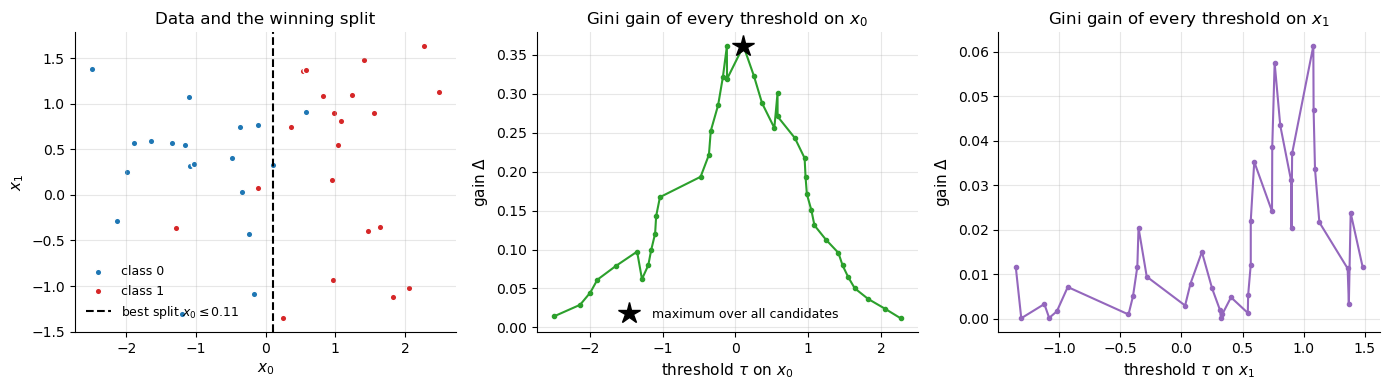

scan winner: feature 0, threshold 0.1104, gain 0.3613


In [15]:
# A simple two-class data set with one informative direction
Xb, yb = make_blobs(40, centers=[[-1.0, 0.0], [1.2, 0.6]], std=0.8)

# Illustration only — exhaustive scan of Eqs. (4)-(5) written independently of the repo
def scan_gains(X, y):
    rows = []
    for j in range(X.shape[1]):
        for tau in np.unique(X[:, j]):                        # candidate thresholds = distinct observed values
            left = X[:, j] <= tau
            if 0 < left.sum() < len(y):                        # both children non-empty
                g = gini_formula(y) - (left.mean() * gini_formula(y[left]) + (1 - left.mean()) * gini_formula(y[~left]))
                rows.append((j, tau, g))
    return rows

scan = scan_gains(Xb, yb)
j_s, tau_s, g_s = max(scan, key=lambda r: r[2])               # max() keeps the FIRST maximum, like the repo

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for k in (0, 1):
    axes[0].scatter(Xb[yb == k, 0], Xb[yb == k, 1], c=CLASS_COLORS[k], s=22, edgecolor="white", label=f"class {k}")
(axes[0].axvline if j_s == 0 else axes[0].axhline)(tau_s, color="k", ls="--", label=f"best split $x_{j_s} \\leq {tau_s:.2f}$")
axes[0].set(title="Data and the winning split", xlabel="$x_0$", ylabel="$x_1$"); axes[0].legend()
for j in (0, 1):
    rows = [(t, g) for jj, t, g in scan if jj == j]
    axes[j + 1].plot(*zip(*rows), "o-", ms=3, color=CLASS_COLORS[j + 2])
    if j == j_s:
        axes[j + 1].plot(tau_s, g_s, "k*", ms=16, label="maximum over all candidates")
        axes[j + 1].legend()
    axes[j + 1].set(title=f"Gini gain of every threshold on $x_{j}$", xlabel=f"threshold $\\tau$ on $x_{j}$", ylabel="gain $\\Delta$")
plt.tight_layout(); plt.show()
print(f"scan winner: feature {j_s}, threshold {tau_s:.4f}, gain {g_s:.4f}")

On $x_0$, the feature along which the two class centres are far apart, the gain rises as the threshold moves into the region between the classes and falls again beyond it. It is near $0$ at the extremes, where one child is almost the whole node. On $x_1$, where the centres are close, every threshold leaves both children mixed, so the gain stays small everywhere (note the very different vertical scales). The winner is the peak of the $x_0$ curve. The curves are jagged because the gain changes only when a sample crosses from one side to the other.

**Your implementation.** `get_best_split(dataset, num_samp, num_feat)` performs this search. `dataset` is the feature matrix with the labels appended as the last column. The method returns a dictionary with the winning `feature_index`, `threshold` and `info_gain`, plus the two child data sets.

In [16]:
best = clf.get_best_split(np.c_[Xb, yb], *Xb.shape)
print({k: (f"array of shape {v.shape}" if isinstance(v, np.ndarray) else v) for k, v in best.items()})

{'feature_index': 0, 'threshold': np.float64(0.11043668894501946), 'dataset_left': 'array of shape (20, 3)', 'dataset_right': 'array of shape (20, 3)', 'info_gain': 0.36125}


In [17]:
# Check — the repo's search returns the arg-max of the independent scan, Eq. (5)
assert best["feature_index"] == j_s and best["threshold"] == tau_s
assert np.isclose(best["info_gain"], g_s)
assert len(best["dataset_left"]) == np.sum(Xb[:, j_s] <= tau_s) and len(best["dataset_right"]) == np.sum(Xb[:, j_s] > tau_s)
print(f"✓ get_best_split chose x_{j_s} <= {tau_s:.4f} with gain {g_s:.4f}: the maximum over all {len(scan)} candidates")

✓ get_best_split chose x_0 <= 0.1104 with gain 0.3613: the maximum over all 78 candidates


The repo's search found the same split as the independent scan: same feature, same threshold, same gain, same child sizes. This confirms that `get_best_split` implements Eqs. (4)–(5).

> 🔧 **Fixed in the code — the impurity measure can now be chosen.**
> *Originally:* `information_gain` had a `mode` parameter whose default is `'entropy'`, but `get_best_split` always called it with the hard-coded string `'gini'`. With no constructor argument for the criterion, `entropy()` was never used when a tree was fitted.
> *Now:* `DecisionTreeClassifier(..., criterion='gini')` accepts `'gini'` (the default, so earlier results are unchanged) or `'entropy'`. `get_best_split` passes `self.criterion` to `information_gain` (DecisionTree.py, line 87). The cell below confirms that the stored gain of a split is measured with whichever criterion was chosen. Section 7.4 shows that the two criteria usually agree anyway.

In [18]:
yL_best, yR_best = best["dataset_left"][:, -1], best["dataset_right"][:, -1]
gini_g = clf.information_gain(yb, yL_best, yR_best, "gini")
ent_g  = clf.information_gain(yb, yL_best, yR_best, "entropy")
print(f"default (gini) tree : stored info_gain = {best['info_gain']:.4f} | Gini gain of that split = {gini_g:.4f}")
assert np.isclose(best["info_gain"], gini_g)

clf_ent = DecisionTreeClassifier(criterion="entropy")
best_ent = clf_ent.get_best_split(np.c_[Xb, yb], *Xb.shape)
ent_check = clf_ent.information_gain(yb, best_ent["dataset_left"][:, -1], best_ent["dataset_right"][:, -1], "entropy")
print(f"criterion='entropy': chose x_{best_ent['feature_index']} <= {best_ent['threshold']:.4f}, stored gain {best_ent['info_gain']:.4f} = entropy gain {ent_check:.4f}")
assert np.isclose(best_ent["info_gain"], ent_check)

default (gini) tree : stored info_gain = 0.3613 | Gini gain of that split = 0.3613
criterion='entropy': chose x_0 <= 0.1104, stored gain 0.6205 = entropy gain 0.6205


> ⚠️ **Note on the implementation — thresholds sit *on* a training point, not between points.**
> Because the candidate thresholds are observed values and the test is `<=`, the decision boundary passes exactly through the largest training value that goes left. Any new point slightly to the right of that value goes right, even if it is much closer to the left group. Most production implementations (e.g. scikit-learn's CART) use the **midpoint** between consecutive distinct values, which puts the boundary halfway across the gap. The two choices produce the same partition of the *training* data, so the tree has the same training accuracy, but they generalise differently to points that fall inside the gap. The [gradient-boosting](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) trees in this repo do use midpoints.

In [19]:
# Two training points: x = 1 (class 0) and x = 3 (class 1). Where does the repo put the boundary?
t2 = DecisionTreeClassifier(min_samp_split=2, max_depth=1)
t2.fit(np.array([[1.0], [3.0]]), np.array([[0.0], [1.0]]))
t2.print_tree()
probe = np.array([[1.0], [1.1], [2.0], [2.9]])
print("x          :", probe.ravel())
print("prediction :", np.array(t2.predict(probe)))

X_0 <= 1.0 ? 0.5
    left:0.0
    right:1.0
x          : [1.  1.1 2.  2.9]
prediction : [0. 1. 1. 1.]


The learned rule is $x_0 \le 1$, so the point $x = 1.1$, which lies right next to the class-0 training point, is assigned class 1. With a midpoint threshold ($\tau = 2$) it would be assigned class 0. The effect matters most for small data sets and coarse features, where gaps between consecutive values are wide.

### 4.4 Recursion, stopping rules and leaf values

**Concept.** Growing the tree is a recursion: find the best split of the current node, partition its data into two child nodes, and grow each child the same way. The recursion stops at a node, which then becomes a *leaf*, when any of these holds:

1. the node has fewer than `min_samp_split` samples;
2. the node is at the depth limit set by `max_depth`;
3. the best available split has gain $\Delta \le 0$. By §4.2 this happens only when every candidate leaves the class mix unchanged, which includes the case of a pure node (every split of a pure node has $\Delta = 0$).

In pseudo-code (compare with `build_tree`, DecisionTree.py lines 42–67):

```
build(S, depth):
    if |S| >= min_samp_split and (max_depth is None or depth < max_depth):
        (j*, τ*, Δ*) = best split of S                    # Eq. (5); empty if no threshold separates S
        if Δ* > 0:
            return Node(j*, τ*, build(S_L, depth+1), build(S_R, depth+1), Δ*)
    return Leaf(value = majority class of S)              # Eq. (6)
```

**Math: the leaf value.** A leaf $\ell$ that predicts class $c$ for all of its training samples $S_\ell$ makes $|S_\ell|\,(1 - p_c(S_\ell))$ training errors. This is minimised by the class with the largest proportion:

$$
v_\ell \;=\; \arg\max_{k}\; p_k(S_\ell) \;=\; \arg\max_k \sum_{i \in S_\ell} \mathbb{1}[y_i = k]. \tag{6}
$$

This is also the plug-in Bayes rule. The leaf's proportions $p_k(S_\ell)$ estimate $P(y = k \mid x \in R_\ell)$, and Eq. (6) takes their argmax, just as $f^*$ does in Section 2.

**Illustration, your implementation, and check.** The illustration computes the majority with `np.bincount`; `calculate_leaf_value(y)` is the repo's version.

In [20]:
# Illustration only — Eq. (6) via counting
def majority_formula(y):
    return float(np.argmax(np.bincount(y.astype(int))))

leaf_examples = [np.array([2., 0, 2, 1, 2]), np.array([0., 0, 1]), np.array([1., 0, 0, 1]), np.array([0., 1, 1, 0])]
for y_leaf in leaf_examples:
    print(f"y = {str(y_leaf):<22} majority by counting = {majority_formula(y_leaf)}   calculate_leaf_value = {clf.calculate_leaf_value(y_leaf)}")

y = [2. 0. 2. 1. 2.]       majority by counting = 2.0   calculate_leaf_value = 2.0
y = [0. 0. 1.]             majority by counting = 0.0   calculate_leaf_value = 0.0
y = [1. 0. 0. 1.]          majority by counting = 0.0   calculate_leaf_value = 0.0
y = [0. 1. 1. 0.]          majority by counting = 0.0   calculate_leaf_value = 0.0


In [21]:
# Check — agreement on 300 random label vectors, ties included
for _ in range(300):
    y_rand = rng.integers(0, 3, size=rng.integers(1, 15)).astype(float)
    assert clf.calculate_leaf_value(y_rand) == majority_formula(y_rand)
print("✓ calculate_leaf_value returns the majority class of Eq. (6), with ties going to the smaller label")

✓ calculate_leaf_value returns the majority class of Eq. (6), with ties going to the smaller label


`calculate_leaf_value` implements Eq. (6), including the last two examples, where classes 0 and 1 are tied 2–2 and both methods return the smaller label.

> 🔧 **Fixed in the code — tie-breaking no longer depends on sample order.**
> *Originally:* the leaf value was `max(y, key=y.count)`, which on a tie returns whichever class *appears first in the list*. For example, `[1, 0, 0, 1]` gave 1 and `[0, 1, 1, 0]` gave 0. The prediction therefore depended on the order of the rows, which in turn depends on how earlier splits shuffled them.
> *Now:* `calculate_leaf_value` counts classes with `np.unique(y, return_counts=True)` and takes the first maximum, so ties always go to the smallest label (DecisionTree.py, lines 130–133).

> 🔧 **Fixed in the code — `max_depth` now means what it says.**
> *Originally:* the depth test in `build_tree` was `curr_depth <= self.max_depth`. The root is at depth 0, so splitting was still allowed at depth `max_depth`, and leaves appeared at depth `max_depth + 1`; even `max_depth=0` split the root once. One practical consequence: `Main.py` compares this tree with scikit-learn's at `max_depth=3`, so the repo's tree was one level deeper.
> *Now:* the test is `curr_depth < self.max_depth` (DecisionTree.py, lines 49–50), the convention used by scikit-learn and by the other trees in this repo. `max_depth=None` means "no depth limit". To reproduce a tree from before the fix, add 1 to `max_depth`.

In [22]:
# Requested max_depth vs. the depth of the tree actually grown on the XOR data
print("max_depth | actual depth | leaves")
for md in [0, 1, 2, 3, 4, 5, None]:
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=md)
    t.fit(X_xor, y_xor.reshape(-1, 1))
    print(f"{str(md):>9} | {tree_depth(t.root):>12} | {count_leaves(t.root):>6}")
    if md is not None:
        assert tree_depth(t.root) == md
print("✓ every tree is exactly as deep as max_depth allows (max_depth=0 is a single leaf)")

max_depth | actual depth | leaves
        0 |            0 |      1
        1 |            1 |      2
        2 |            2 |      4


        3 |            3 |      8


        4 |            4 |     13
        5 |            5 |     19


     None |            7 |     29
✓ every tree is exactly as deep as max_depth allows (max_depth=0 is a single leaf)


Each tree is exactly `max_depth` deep. `max_depth=0` gives a single leaf that predicts the majority class, and `max_depth=None` grows the tree until every leaf is pure.

> 🔧 **Fixed in the code — nodes whose rows are all identical used to crash `fit`.**
> *Originally:* if every sample in a node had the same feature vector, no threshold could produce two non-empty children, so `get_best_split` returned an empty dictionary. `build_tree` then evaluated `best_split['info_gain']` and raised `KeyError: 'info_gain'`, even when the node was pure. This happened with duplicated rows, discrete features with few values, and above all with bootstrap samples (the [Random Forest notebook](../RandomForest/RandomForest_Walkthrough.ipynb) analyses how often).
> *Now:* `build_tree` tests `best_split.get('info_gain', -inf) > 0` (line 56). A node with no valid split simply becomes a leaf, which is what scikit-learn does.

In [23]:
cases = [(np.array([[1.0], [1.0], [1.0]]), np.array([[0.0], [1.0], [1.0]]), "identical x, mixed labels"),
         (np.array([[2.0, 5.0], [2.0, 5.0]]), np.array([[1.0], [1.0]]), "identical x, pure node")]
for X_dup, y_dup, desc in cases:
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=3)
    t.fit(X_dup, y_dup)
    print(f"{desc:<26}: fit succeeded -> a single leaf predicting {t.root.value}  (depth {tree_depth(t.root)})")
    assert t.root.value is not None

identical x, mixed labels : fit succeeded -> a single leaf predicting 1.0  (depth 0)
identical x, pure node    : fit succeeded -> a single leaf predicting 1.0  (depth 0)


Both cases that used to crash now produce a single leaf. In the mixed case, the leaf predicts the majority label 1 (two of the three samples), which is the best any model can do for three identical inputs.

### 4.5 Prediction: routing a point to its leaf

**Concept and math.** To classify a new point $x$, start at the root. At a decision node $(j, \tau)$, go left if $x_j \le \tau$ and right otherwise, until you reach a leaf. The answer is that leaf's value. Because the leaves' regions $R_\ell$ partition the space, this computes Eq. (0), $\hat f(x) = \sum_\ell v_\ell \mathbb{1}[x \in R_\ell]$, by evaluating only the single indicator that is non-zero. A prediction costs one comparison per level, $O(\text{depth})$, no matter how many training samples there were.

**Illustration.** A hand-written traversal that reads the attributes of your `Node` objects and records the path.

In [24]:
# Illustration only — route a point through the Node objects by hand, recording each comparison
def route(x, node):
    path = []
    while node.value is None:                                  # decision node
        go_left = x[node.feature_index] <= node.threshold
        path.append(f"x_{node.feature_index}={x[node.feature_index]:+.3f} {'<=' if go_left else '> '} {node.threshold:+.3f}")
        node = node.left if go_left else node.right
    return node.value, path

value, path = route(X_xor_test[0], clf_preview.root)
print("point:", X_xor_test[0], "\npath :", "  ->  ".join(path), f"\nleaf value: {value}")

point: [-0.9876  0.4423] 
path : x_1=+0.442 >  -0.233  ->  x_0=-0.988 <= -0.022  ->  x_1=+0.442 >  -0.066 
leaf value: 1.0


**Your implementation.** `predict(X)` calls the recursive `make_prediction(x, self.root)` once per row and returns a Python list.

In [25]:
# Check — the repo's predict agrees with the hand traversal on all 2,000 test points
pred_repo = np.array(clf_preview.predict(X_xor_test))
pred_hand = np.array([route(x, clf_preview.root)[0] for x in X_xor_test])
assert np.array_equal(pred_repo, pred_hand)
print(f"✓ predict() == manual routing for all {len(X_xor_test)} test points")

✓ predict() == manual routing for all 2000 test points


`make_prediction` implements the root-to-leaf routing exactly as described: `<=` goes left, `>` goes right, and the leaf's stored value is returned.

## 5. Implementation walkthrough, in the order the code runs

Calling `fit(X, Y)` and then `predict(X_new)` runs the methods in this order:

```
fit(X, Y) ── validate, concatenate X and Y ──> build_tree(dataset, depth=0)
                                       ├── get_best_split(dataset, n, m)
                                       │      └── for each feature j, each unique value τ:
                                       │              split(dataset, j, τ)                   → S_L, S_R
                                       │              information_gain(..., self.criterion)  → gini_index or entropy ×3
                                       ├── if gain > 0: Node(j, τ, build_tree(S_L), build_tree(S_R), gain)
                                       └── else:        Node(value = calculate_leaf_value(y))
predict(X_new) ── for each row ──> make_prediction(x, root)  (recursive descent)
```

**`Node` (lines 16–26).** A single class represents both kinds of node. A *decision node* stores `feature_index` ($j$), `threshold` ($\tau$), the `left` and `right` children, and `info_gain` (the $\Delta$ of Eq. (3) that won the search; it is used only for printing). A *leaf* stores only `value` ($v_\ell$ of Eq. (6)), and its other fields remain `None`. All the traversal code tells the two apart by testing whether `value` is `None`. The training data are **not** stored in the nodes. Once `fit` returns, the tree is just these thresholds and labels.

**`DecisionTreeClassifier.__init__(min_samp_split=2, max_depth=2, criterion='gini')` (lines 29–40).** Stores the stopping rules (`max_depth=None` means unlimited) and the impurity criterion, rejecting anything other than `'gini'` or `'entropy'`.

**`fit(X, Y)` (lines 148–163).**
```python
X = np.asarray(X)
Y = np.asarray(Y)
if Y.ndim == 1:
    Y = Y.reshape(-1, 1)
...                                   # shape checks: ValueError for mismatched or empty input
if Y.dtype.kind not in 'biuf':
    Y = Y.astype(object)
dataset = np.concatenate((X, Y), axis=1)
self.root = self.build_tree(dataset)
```
The labels are appended to the features as an extra last column, so every method downstream splits rows of one combined array and the labels always travel with their features.

> 🔧 **Fixed in the code — `fit` now accepts 1-D labels and string labels.**
> *Originally:* `fit` was just the concatenation. A 1-D label vector made `np.concatenate` raise `ValueError`. Worse, NumPy *string* labels (dtype `<U…`) silently converted **every** column of the combined array to strings, because a NumPy array has a single dtype. The split search then compared feature values *lexicographically*. For example, `'9.0' > '12.0'` as strings, so the number 9 was treated as the *largest* value: data that one threshold separates perfectly needed two splits, and `predict` then crashed comparing float inputs with string thresholds.
> *Now:* `Y` is reshaped to a column if needed, and any non-numeric label array is cast to `object` dtype before the concatenation. Features then stay numbers inside an object array, and comparisons stay numeric. The cell below repeats both original failure cases.

In [26]:
t1d = DecisionTreeClassifier(max_depth=3); t1d.fit(X_xor, y_xor)               # 1-D labels
print("1-D labels: fit works; training accuracy =", np.mean(np.array(t1d.predict(X_xor)) == y_xor))

X_s = np.array([[9.0], [10.0], [11.0], [12.0]])           # perfectly separable: 9, 10 -> 'a'; 11, 12 -> 'b'
y_str = np.array(["a", "a", "b", "b"])                    # NumPy string labels (dtype <U1)
t_str = DecisionTreeClassifier(max_depth=2); t_str.fit(X_s, y_str)
t_str.print_tree()
print("predict([9.5, 11.5]) =", t_str.predict(np.array([[9.5], [11.5]])))
assert t_str.predict(np.array([[9.5], [11.5]])) == ["a", "b"] and t_str.root.threshold == 10.0

1-D labels: fit works; training accuracy = 0.94
X_0 <= 10.0 ? 0.5
    left:a
    right:b
predict([9.5, 11.5]) = ['a', 'b']


With string labels the tree is now a single correct split, `X_0 <= 10.0`, the same as with numeric labels, and prediction returns the string classes.

**`build_tree(dataset, curr_depth=0)` (lines 42–67).** It separates the features `X = dataset[:, :-1]` from the labels `Y = dataset[:, -1]` and checks the two stopping rules (sample count, and depth via `depth_ok`). It calls `get_best_split` and, if the winning gain is positive (stopping rule 3; an empty result counts as "no positive gain"), recurses on the left and right child data sets with `curr_depth + 1` and returns a decision `Node`. In every other case it returns a leaf whose value comes from `calculate_leaf_value(Y)`.

**`get_best_split(dataset, num_samp, num_feat)` (lines 69–98).** This is Eqs. (4)–(5). The outer loop runs over features; `possible_thresholds = np.unique(feature_values)` lists the sorted distinct values, and the inner loop tries each one. A candidate is kept only if both children are non-empty, and it replaces the current best only if its gain is **strictly** larger (first-wins tie-breaking). The gain is measured with `self.criterion`. The returned dictionary also carries copies of the two child data sets, which `build_tree` passes down the recursion.

**`split(dataset, feature_index, threshold)` (lines 109–112).**
```python
dataset_left = np.array([row for row in dataset if row[feature_index]<=threshold])
dataset_right = np.array([row for row in dataset if row[feature_index]>threshold])
```
This defines $S_L$ and $S_R$. It walks over the rows in a Python list comprehension and copies them into new arrays. That is correct but slow: $O(|S|)$ Python-level work for **every** candidate threshold. Section 9 measures what this costs.

**`information_gain`, `gini_index`, `entropy` (lines 100–128).** These are Eqs. (3), (1) and (2), already checked in §4.1–4.2. The child weights are `len(l_child) / len(parent)`.

**`calculate_leaf_value(y)` (lines 130–133).** This is Eq. (6), checked in §4.4.

**`print_tree(tree=None, indent='    ')` (lines 135–146).** A pre-order printout: a decision node prints as `X_j <= τ ? gain`, followed by its `left:` and `right:` subtrees with doubled indentation. A leaf prints as its value.

**`predict(X)` and `make_prediction(x, tree)` (lines 165–178).** The recursive descent of §4.5. A node is recognised as a leaf with `tree.value is not None`. (The original `tree.value != None` worked for scalar labels, but `!=` on NumPy values performs an element-wise comparison, so the identity test is the safe idiom.)

**The other files.** `GetKaggleDataset.get_dataset(dataset_id, filename)` downloads a Kaggle dataset with `kagglehub` (cached after the first call) and loads a CSV with pandas. `Main.py` uses it to fit this tree to the Iris data and compares it with scikit-learn's `DecisionTreeClassifier`, including a `GridSearchCV` over hyperparameters. Both need network access or scikit-learn, so this notebook does not run them.

## 6. Worked numerical example

We now grow a tree on 8 hand-sized samples and print **every** intermediate number. The data have two features and two classes, four samples each.

  i   x0   x1   y
  0    1    1   1
  1    3    7   0
  2    4    6   1
  3    5    5   1
  4    6    3   0
  5    7    9   0
  6    8    4   0
  7    9    8   1


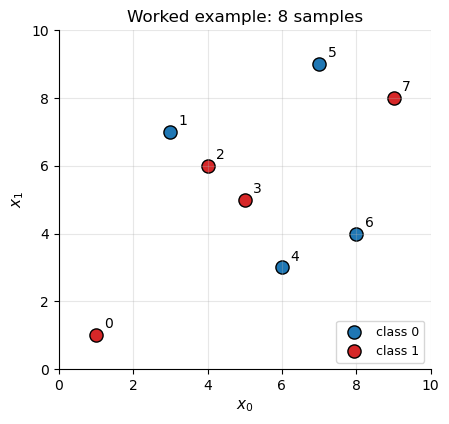

In [27]:
# The worked-example data set (sorted by x0 for readability)
X_toy = np.array([[1, 1], [3, 7], [4, 6], [5, 5], [6, 3], [7, 9], [8, 4], [9, 8]], dtype=float)
y_toy = np.array([1, 0, 1, 1, 0, 0, 0, 1], dtype=float)
ds_toy = np.c_[X_toy, y_toy]                                  # the format build_tree works with: [x0, x1, y]

print("  i   x0   x1   y")
for i, (a, b_, c) in enumerate(ds_toy):
    print(f"{i:>3} {a:>4.0f} {b_:>4.0f} {c:>3.0f}")

fig, ax = plt.subplots(figsize=(4.8, 4.4))
for k in (0, 1):
    m = y_toy == k
    ax.scatter(X_toy[m, 0], X_toy[m, 1], s=90, c=CLASS_COLORS[k], edgecolor="k", label=f"class {k}")
for i, (a, b_) in enumerate(X_toy):
    ax.annotate(str(i), (a, b_), textcoords="offset points", xytext=(6, 5))
ax.set(title="Worked example: 8 samples", xlabel="$x_0$", ylabel="$x_1$", xlim=(0, 10), ylim=(0, 10))
ax.legend(loc="lower right", frameon=True); plt.show()

**Step 1: impurity of the root.** Four samples of each class give $p_0 = p_1 = 0.5$, so by Eq. (1) $G(S) = 1 - (0.5^2 + 0.5^2) = 0.5$, the maximum for $K = 2$.

In [28]:
print(f"G(root) by hand       = 1 - (0.5^2 + 0.5^2) = {1 - 0.5**2 - 0.5**2}")
print(f"G(root) by gini_index = {clf.gini_index(y_toy)}")

G(root) by hand       = 1 - (0.5^2 + 0.5^2) = 0.5
G(root) by gini_index = 0.5


**Step 2: score every candidate split of the root.** For each feature and each distinct value $\tau$, the table lists the child sizes, the child Gini values, and the gain of Eq. (3), all computed by calling the repo's `split`, `gini_index` and `information_gain`. The largest value $\tau = 9$ is absent because it would leave the right child empty.

In [29]:
def candidate_table(ds, title):
    """Print every candidate split of a node, scored with the repo's own split / gini_index / information_gain."""
    y = ds[:, -1]
    rows = []
    for j in range(ds.shape[1] - 1):
        for tau in np.unique(ds[:, j]):
            L, R = clf.split(ds, j, tau)
            if len(L) and len(R):
                rows.append((j, tau, len(L), len(R), clf.gini_index(L[:, -1]), clf.gini_index(R[:, -1]),
                             clf.information_gain(y, L[:, -1], R[:, -1], "gini")))
    best_gain = max(r[-1] for r in rows)
    print(title)
    print("  j   tau | |S_L| |S_R| |  G(S_L)  G(S_R) |   gain")
    for j, tau, nL, nR, gL_, gR_, g in rows:
        mark = "  <- best" if np.isclose(g, best_gain) else ""
        print(f"  {j} {tau:>5.0f} | {nL:>5} {nR:>5} | {gL_:>7.4f} {gR_:>7.4f} | {g:>6.4f}{mark}")

candidate_table(ds_toy, "Root node (8 samples, G = 0.5):")

Root node (8 samples, G = 0.5):
  j   tau | |S_L| |S_R| |  G(S_L)  G(S_R) |   gain
  0     1 |     1     7 |  0.0000  0.4898 | 0.0714
  0     3 |     2     6 |  0.5000  0.5000 | 0.0000
  0     4 |     3     5 |  0.4444  0.4800 | 0.0333
  0     5 |     4     4 |  0.3750  0.3750 | 0.1250  <- best
  0     6 |     5     3 |  0.4800  0.4444 | 0.0333
  0     7 |     6     2 |  0.5000  0.5000 | 0.0000
  0     8 |     7     1 |  0.4898  0.0000 | 0.0714
  1     1 |     1     7 |  0.0000  0.4898 | 0.0714
  1     3 |     2     6 |  0.5000  0.5000 | 0.0000
  1     4 |     3     5 |  0.4444  0.4800 | 0.0333
  1     5 |     4     4 |  0.5000  0.5000 | 0.0000
  1     6 |     5     3 |  0.4800  0.4444 | 0.0333
  1     7 |     6     2 |  0.5000  0.5000 | 0.0000
  1     8 |     7     1 |  0.4898  0.0000 | 0.0714


The winner is $x_0 \le 5$, with gain $0.125$. It sends samples 0–3 left (three of class 1, one of class 0) and samples 4–7 right (three of class 0, one of class 1). Each child has $G = 1 - (0.75^2 + 0.25^2) = 0.375$, so the gain is $0.5 - (\tfrac48 \cdot 0.375 + \tfrac48 \cdot 0.375) = 0.125$. No other candidate does as well. The runners-up, tied at about $0.071$, each peel a single sample off one end of the data. For example, $x_1 \le 1$ isolates sample 0, which leaves a right child of 7 samples that is still almost evenly mixed. Note what the gain does *not* reward: $x_0 \le 5$ produces no pure child, yet it is the best first move because it makes both halves lopsided. (`get_best_split` returns the same answer, as the next cell confirms.)

In [30]:
root_split = clf.get_best_split(ds_toy, *X_toy.shape)
print(f"get_best_split: feature {root_split['feature_index']}, threshold {root_split['threshold']}, gain {root_split['info_gain']:.4f}")
print("left child rows :", root_split["dataset_left"][:, :2].tolist(), "labels", root_split["dataset_left"][:, -1])
print("right child rows:", root_split["dataset_right"][:, :2].tolist(), "labels", root_split["dataset_right"][:, -1])

get_best_split: feature 0, threshold 5.0, gain 0.1250
left child rows : [[1.0, 1.0], [3.0, 7.0], [4.0, 6.0], [5.0, 5.0]] labels [1. 0. 1. 1.]
right child rows: [[6.0, 3.0], [7.0, 9.0], [8.0, 4.0], [9.0, 8.0]] labels [0. 0. 0. 1.]


**Step 3: recurse into the left child** (samples 0–3, labels $1, 0, 1, 1$, $G = 0.375$).

In [31]:
candidate_table(root_split["dataset_left"], "Left child (samples 0-3, G = 0.375):")

Left child (samples 0-3, G = 0.375):
  j   tau | |S_L| |S_R| |  G(S_L)  G(S_R) |   gain
  0     1 |     1     3 |  0.0000  0.4444 | 0.0417
  0     3 |     2     2 |  0.5000  0.0000 | 0.1250
  0     4 |     3     1 |  0.4444  0.0000 | 0.0417
  1     1 |     1     3 |  0.0000  0.4444 | 0.0417
  1     5 |     2     2 |  0.0000  0.5000 | 0.1250
  1     6 |     3     1 |  0.0000  0.0000 | 0.3750  <- best


Only one candidate isolates sample 1, the single class-0 point: $x_1 \le 6$ sends samples 0, 2 and 3 (all class 1) left and sample 1 right. Both children are pure, so its gain is $0.375$, the parent's *entire* impurity and the largest gain possible here. Every other candidate leaves sample 1 in a mixed child; for example, $x_0 \le 3$ puts it together with sample 0 and gains only $0.125$. Both children of the winning split are pure, so the recursion stops in each of them by rule 3.

**Step 4: recurse into the right child** (samples 4–7, labels $0, 0, 0, 1$).

In [32]:
candidate_table(root_split["dataset_right"], "Right child (samples 4-7, G = 0.375):")

Right child (samples 4-7, G = 0.375):
  j   tau | |S_L| |S_R| |  G(S_L)  G(S_R) |   gain
  0     6 |     1     3 |  0.0000  0.4444 | 0.0417
  0     7 |     2     2 |  0.0000  0.5000 | 0.1250
  0     8 |     3     1 |  0.0000  0.0000 | 0.3750  <- best
  1     3 |     1     3 |  0.0000  0.4444 | 0.0417
  1     4 |     2     2 |  0.0000  0.5000 | 0.1250
  1     8 |     3     1 |  0.4444  0.0000 | 0.0417


Here $x_0 \le 8$ separates sample 7 (the only class 1) from samples 4–6, again leaving two pure children with gain $0.375$.

**Step 5: the full tree from `fit`.** The repo's `fit` should reproduce exactly the tree built by hand: root $x_0 \le 5$; left child $x_1 \le 6$; right child $x_0 \le 8$; four pure leaves.

In [33]:
toy_tree = DecisionTreeClassifier(min_samp_split=2, max_depth=5)
toy_tree.fit(X_toy, y_toy.reshape(-1, 1))
toy_tree.print_tree()

r = toy_tree.root
assert (r.feature_index, r.threshold) == (0, 5.0)
assert (r.left.feature_index, r.left.threshold, r.left.left.value, r.left.right.value) == (1, 6.0, 1.0, 0.0)
assert (r.right.feature_index, r.right.threshold, r.right.left.value, r.right.right.value) == (0, 8.0, 0.0, 1.0)
assert np.array_equal(np.array(toy_tree.predict(X_toy)), y_toy)
print("\n✓ fit() built exactly the tree derived by hand, and it classifies all 8 training samples correctly")

X_0 <= 5.0 ? 0.125
    left:X_1 <= 6.0 ? 0.375
        left:1.0
        right:0.0
    right:X_0 <= 8.0 ? 0.375
        left:0.0
        right:1.0

✓ fit() built exactly the tree derived by hand, and it classifies all 8 training samples correctly


The printed gains ($0.125$ at the root, $0.375$ in both children) are the numbers from the tables above. The tree has depth 2 and stopped because every leaf is pure, not because of `max_depth`.

**Step 6: predict two new points.** We route $x = (2, 2)$ and $x = (8.5, 6)$ through the tree.

x = [2. 2.]:  x_0=+2.000 <= +5.000  ->  x_1=+2.000 <= +6.000  ->  leaf 1.0   (predict: 1.0)
x = [8.5 6. ]:  x_0=+8.500 >  +5.000  ->  x_0=+8.500 >  +8.000  ->  leaf 1.0   (predict: 1.0)


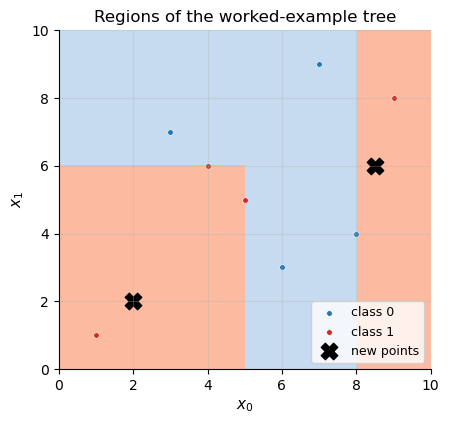

In [34]:
for x_new in np.array([[2.0, 2.0], [8.5, 6.0]]):
    value, path = route(x_new, toy_tree.root)
    print(f"x = {x_new}:  " + "  ->  ".join(path) + f"  ->  leaf {value}   (predict: {toy_tree.predict(x_new[None, :])[0]})")

fig, ax = plt.subplots(figsize=(4.8, 4.4))
plot_decision_regions(toy_tree.predict, X_toy, y_toy, ax=ax, title="Regions of the worked-example tree", pad=1.0, legend=False)
ax.scatter([2, 8.5], [2, 6], marker="X", s=140, c="k", label="new points")
ax.legend(loc="lower right", frameon=True); plt.show()

$(2, 2)$ goes left at the root ($2 \le 5$) and left again ($2 \le 6$), landing in a class-1 leaf. $(8.5, 6)$ goes right ($8.5 > 5$) and then right again ($8.5 > 8$), landing in the class-1 leaf that contains only sample 7. The regions plot shows the four boxes. The boundaries pass exactly through training values ($x_0 = 5$, $x_0 = 8$, $x_1 = 6$), the observed-value thresholds discussed in §4.3. A midpoint rule would put the right-hand boundary at $x_0 = 8.5$, exactly where the second new point sits.

## 7. Visual experiments

### 7.1 Decision regions as the tree grows

We grow trees of increasing depth on the 200-point noisy XOR training set and shade the regions each tree assigns to each class.

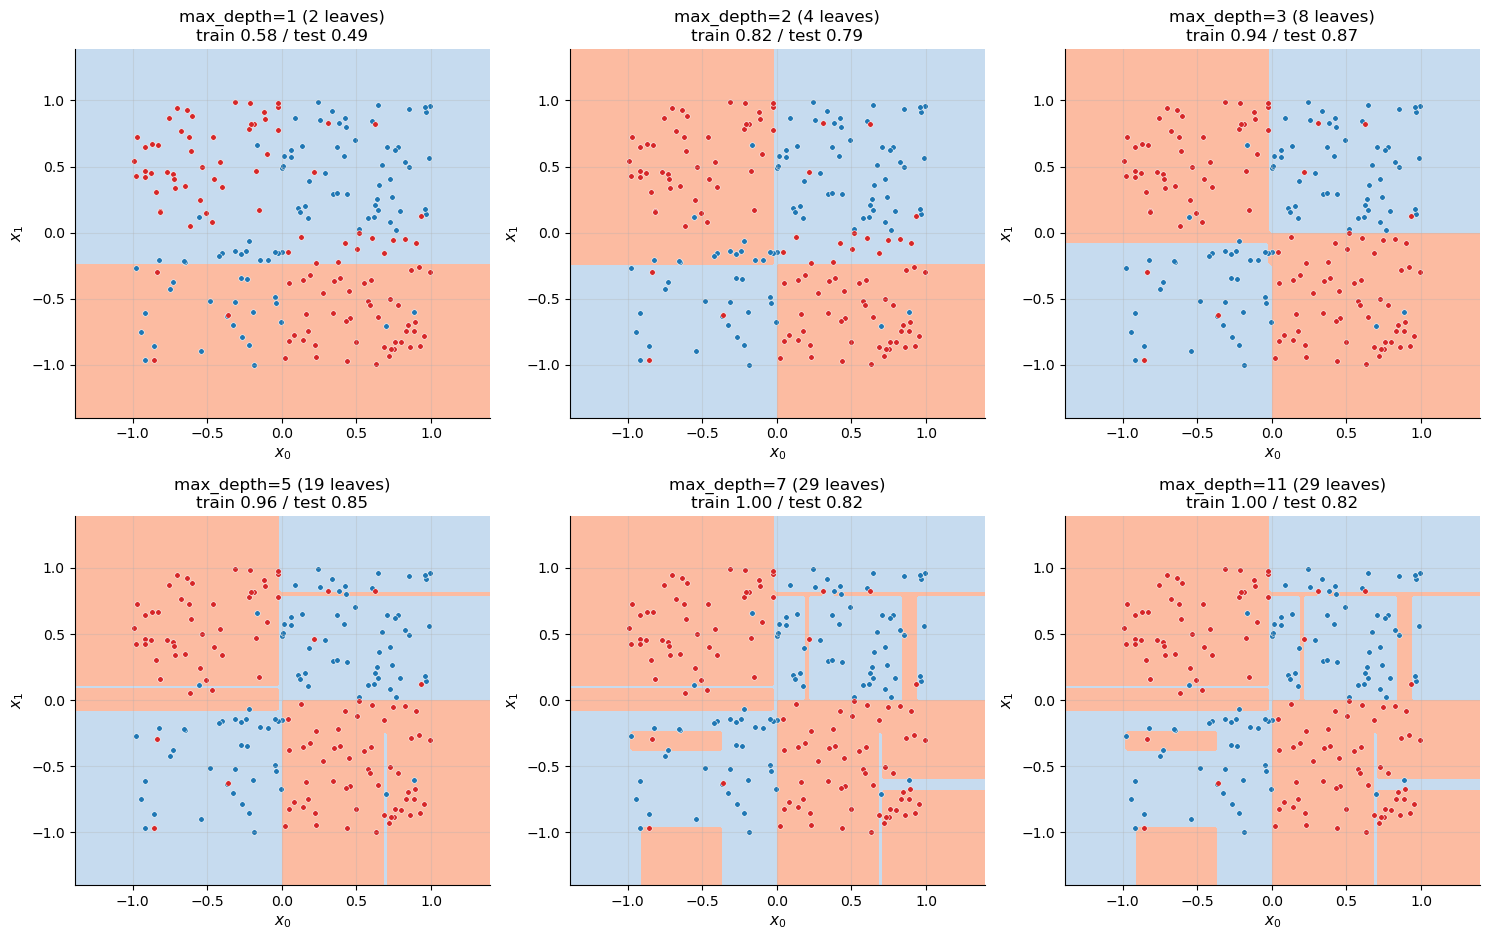

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, md in zip(axes.ravel(), [1, 2, 3, 5, 7, 11]):
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=md); t.fit(X_xor, y_xor.reshape(-1, 1))
    tr = np.mean(np.array(t.predict(X_xor)) == y_xor); te = np.mean(np.array(t.predict(X_xor_test)) == y_xor_test)
    plot_decision_regions(t.predict, X_xor, y_xor, ax=ax, legend=(md == 0),
                          title=f"max_depth={md} ({count_leaves(t.root)} leaves)\ntrain {tr:.2f} / test {te:.2f}")
plt.tight_layout(); plt.show()

What to notice:
- With a single split (top left), the tree cannot represent XOR at all; any one axis-aligned cut leaves both sides mixed, and test accuracy is about chance.
- At depth 2 there are four regions, but the horizontal boundary sits at the greedy root threshold $x_1 \approx -0.23$ instead of $0$. At depth 3 the extra splits move the boundaries close to the true quadrants, and test accuracy reaches its best value, a few points below the 90% ceiling.
- As depth increases further, the tree carves out thin boxes around individual mislabelled points. Training accuracy climbs to 100% while test accuracy falls. These islands are the visual signature of **overfitting**: the tree is memorising the 10% label noise.
- `max_depth=7` and `max_depth=11` give the same tree: by depth 7 every leaf is pure, so stopping rule 3 ends growth before the depth limit matters.

### 7.2 Training and test accuracy versus depth

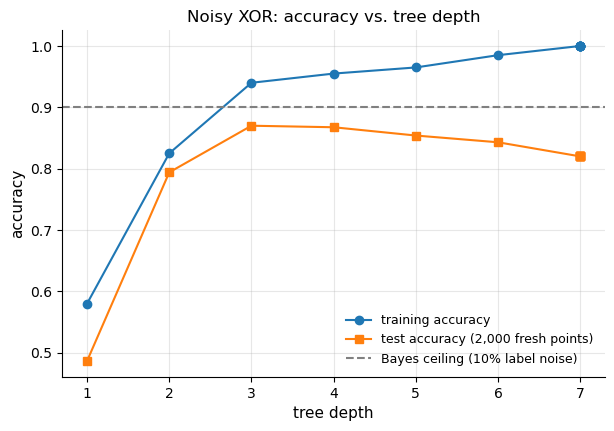

best test accuracy 0.870 at depth 3; deepest tree: train 1.000, test 0.820


In [36]:
depths, tr_acc, te_acc = [], [], []
for md in range(1, 14):
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=md); t.fit(X_xor, y_xor.reshape(-1, 1))
    depths.append(tree_depth(t.root))
    tr_acc.append(np.mean(np.array(t.predict(X_xor)) == y_xor))
    te_acc.append(np.mean(np.array(t.predict(X_xor_test)) == y_xor_test))

fig, ax = plt.subplots()
ax.plot(depths, tr_acc, "o-", label="training accuracy")
ax.plot(depths, te_acc, "s-", label="test accuracy (2,000 fresh points)")
ax.axhline(0.9, color="gray", ls="--", label="Bayes ceiling (10% label noise)")
ax.set(title="Noisy XOR: accuracy vs. tree depth", xlabel="tree depth", ylabel="accuracy")
ax.legend(); plt.show()
print(f"best test accuracy {max(te_acc):.3f} at depth {depths[int(np.argmax(te_acc))]}; "
      f"deepest tree: train {tr_acc[-1]:.3f}, test {te_acc[-1]:.3f}")

This is the bias–variance tradeoff in one picture. Shallow trees **underfit** (high bias): both curves are low because the model cannot represent the quadrants. Test accuracy peaks at a moderate depth, a few points below the 90% ceiling. Beyond that, training accuracy keeps rising to 1, but test accuracy declines, because the extra leaves fit noise (high variance). The curves go flat once the tree is fully grown. The gap between the two curves is the overfitting. `max_depth` is the main dial for choosing a point on this curve.

### 7.3 Greedy myopia: why XOR is hard for a one-step-ahead search

§4.3 chose the split with the best *immediate* gain. On perfectly balanced XOR data, no single axis-aligned split improves purity in expectation: every vertical or horizontal cut leaves each side half class 0 and half class 1. The illustration compares the root gains on noise-free XOR with the gains available one level down, after the "right" split $x_0 \le 0$.

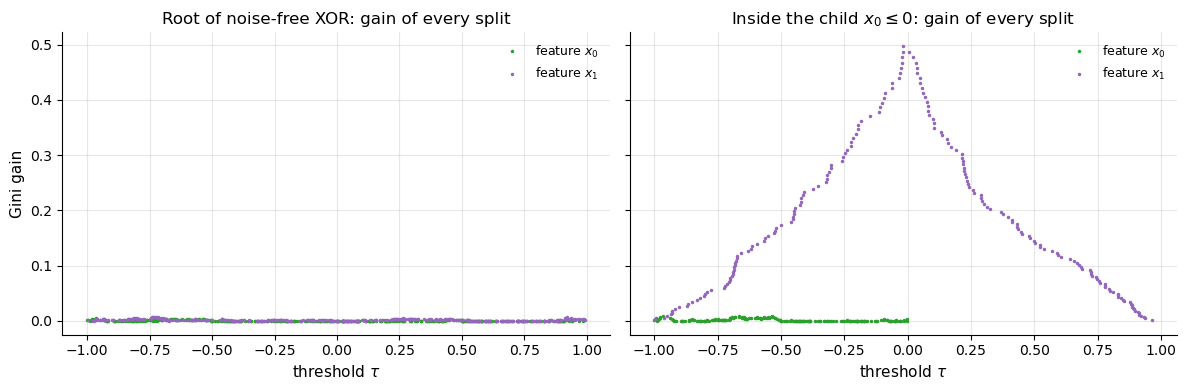

largest root gain:  0.0078
largest child gain: 0.4974   (the maximum possible for a two-class node is 0.5)


In [37]:
X_x0, y_x0 = make_xor(400, noise=0.0)
root_scan = scan_gains(X_x0, y_x0)
left = X_x0[:, 0] <= 0
child_scan = scan_gains(X_x0[left], y_x0[left])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for j in (0, 1):
    rows = [(t, g) for jj, t, g in root_scan if jj == j]
    axes[0].plot(*zip(*rows), ".", ms=3, color=CLASS_COLORS[j + 2], label=f"feature $x_{j}$")
    rows = [(t, g) for jj, t, g in child_scan if jj == j]
    axes[1].plot(*zip(*rows), ".", ms=3, color=CLASS_COLORS[j + 2], label=f"feature $x_{j}$")
axes[0].set(title="Root of noise-free XOR: gain of every split", xlabel="threshold $\\tau$", ylabel="Gini gain")
axes[1].set(title="Inside the child $x_0 \\leq 0$: gain of every split", xlabel="threshold $\\tau$")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
print(f"largest root gain:  {max(g for *_, g in root_scan):.4f}")
print(f"largest child gain: {max(g for *_, g in child_scan):.4f}   (the maximum possible for a two-class node is 0.5)")

At the root every gain is tiny: the best is about one sixtieth of what is available one level down, and it reflects sampling fluctuations rather than structure. Inside the child $x_0 \le 0$, the split $x_1 \le 0$ is worth almost the full $0.5$. A greedy learner cannot know that a near-useless first split will enable a perfect second one, so on XOR-like data its root choice is close to arbitrary. That is exactly what happened on the noisy 200-point training set in §3: the root split was $x_1 \le -0.23$, with gain $0.019$, nowhere near the true boundary. The deeper levels then had to compensate with extra splits. This myopia is a fundamental limitation of greedy tree induction, and one reason ensembles of many trees help.

### 7.4 Gini versus entropy: do they choose different splits?

`fit` always uses Gini (see the Note in §4.3), but `information_gain` can score candidates either way. We count how often the two criteria choose the same best split, over many small random data sets.

Gini and entropy chose the same root split in 160/200 random 30-point data sets (80%)


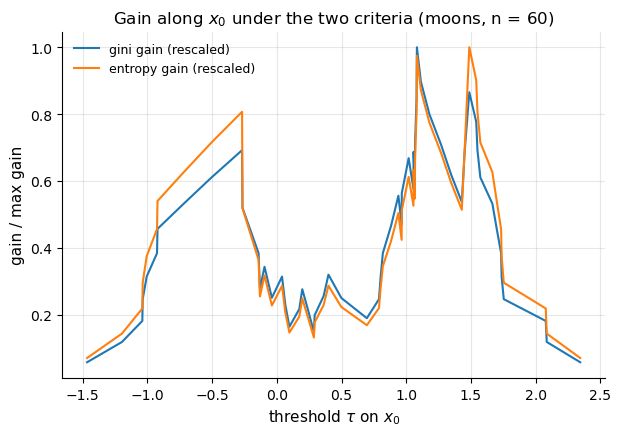

In [38]:
def best_split_by(ds, mode):
    """Arg-max of Eq. (5) using the repo's split + information_gain with the given impurity mode."""
    y = ds[:, -1]; best_c, best_g = None, -np.inf
    for j in range(ds.shape[1] - 1):
        for tau in np.unique(ds[:, j]):
            L, R = clf.split(ds, j, tau)
            if len(L) and len(R):
                g = clf.information_gain(y, L[:, -1], R[:, -1], mode)
                if g > best_g:
                    best_c, best_g = (j, tau), g
    return best_c

agree, trials = 0, 200
for _ in range(trials):
    Xr, yr = make_moons(30, noise=0.35)
    ds = np.c_[Xr, yr]
    agree += best_split_by(ds, "gini") == best_split_by(ds, "entropy")
print(f"Gini and entropy chose the same root split in {agree}/{trials} random 30-point data sets ({agree/trials:.0%})")

# One example: both gain curves along x0, rescaled to a maximum of 1 so their shapes can be compared
Xr, yr = make_moons(60, noise=0.3); ds = np.c_[Xr, yr]
taus = np.unique(Xr[:, 0])[:-1]
curves = {mode: np.array([clf.information_gain(yr, *[part[:, -1] for part in clf.split(ds, 0, t)], mode) for t in taus])
          for mode in ("gini", "entropy")}
fig, ax = plt.subplots()
for mode, c in curves.items():
    ax.plot(taus, c / c.max(), label=f"{mode} gain (rescaled)")
ax.set(title="Gain along $x_0$ under the two criteria (moons, n = 60)", xlabel="threshold $\\tau$ on $x_0$", ylabel="gain / max gain")
ax.legend(); plt.show()

The two criteria pick the same split in most data sets, and the rescaled gain curves track each other closely. That is expected: for two classes, both are symmetric concave functions of $p$ with the same zeros and the same maximiser (§4.1). The example also shows where the disagreements come from. There are two near-equal peaks, around $\tau \approx 1.1$ and $\tau \approx 1.5$. Gini ranks the first slightly higher and entropy the second, because entropy rewards nearly pure children slightly more. When the criteria disagree, it is almost always between candidates of nearly equal quality. Fixing the criterion to Gini therefore costs little in accuracy. Gini is also cheaper, since it needs no logarithms.

### 7.5 Instability: small data changes, different trees

High variance means the fitted tree depends strongly on which training points we happened to observe. We fit the same deep tree to three random 70% subsamples of one data set.

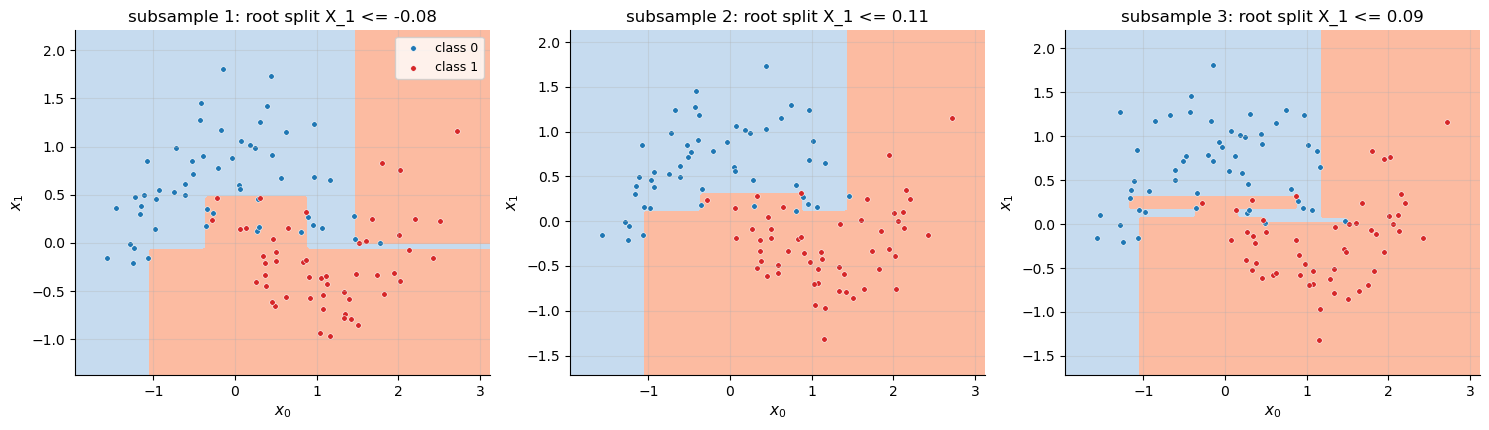

on average the three trees disagree on 6% of a grid covering the data


In [39]:
X_mo, y_mo = make_moons(150, noise=0.3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
grid_preds = []
gx = np.c_[np.repeat(np.linspace(-1.5, 2.5, 60), 60), np.tile(np.linspace(-1.2, 1.7, 60), 60)]
for s, ax in enumerate(axes):
    idx = rng.choice(len(X_mo), size=105, replace=False)       # a different 70% subsample each time
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=6); t.fit(X_mo[idx], y_mo[idx].reshape(-1, 1))
    grid_preds.append(np.array(t.predict(gx)))
    plot_decision_regions(t.predict, X_mo[idx], y_mo[idx], ax=ax, legend=(s == 0),
                          title=f"subsample {s+1}: root split X_{t.root.feature_index} <= {t.root.threshold:.2f}")
plt.tight_layout(); plt.show()
dis = np.mean([np.mean(grid_preds[a] != grid_preds[b]) for a, b in [(0, 1), (0, 2), (1, 2)]])
print(f"on average the three trees disagree on {dis:.0%} of a grid covering the data")

The overall shape is similar, but the root split changes from one subsample to the next, and the details (especially the small boxes in the overlap region) differ. The trees disagree on several percent of the plane, all of it concentrated in the region between the moons where the label is genuinely uncertain. This variance is the motivation for [Random Forests](../RandomForest/RandomForest_Walkthrough.ipynb). Averaging many such trees, each trained on a different resample, cancels much of the disagreement while keeping the flexibility.

## 8. Hyperparameters

`DecisionTreeClassifier(min_samp_split=2, max_depth=2, criterion='gini')` has three hyperparameters. The first two are **pre-pruning** rules: they stop growth early instead of growing a full tree and pruning it back.

- **`max_depth`** caps the number of levels; `None` removes the cap. A small value means a simple model: high bias, low variance. A large value means a complex model: low bias, high variance.
- **`min_samp_split`** forbids splitting a node with fewer than this many samples. Raising it stops the tree from carving out tiny regions around a handful of points. It is a *data-adaptive* complexity control: dense regions can still be split finely, while sparse regions stop early.
- **`criterion`** chooses Gini or entropy; §7.4 shows it rarely matters.

Settings the implementation does not have (compare scikit-learn): `min_samples_leaf` (a minimum child size), `max_features`, `max_leaf_nodes`, a minimum impurity decrease, class weights, and cost-complexity post-pruning (`ccp_alpha`).

The heat-map shows test accuracy over a grid of both hyperparameters on moons data (noise level 0.2).

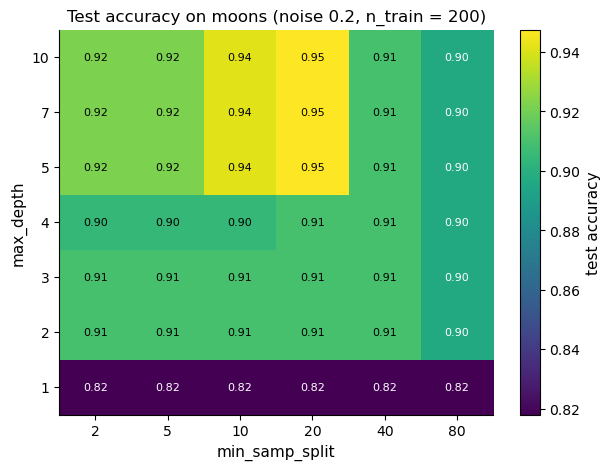

best: max_depth=5, min_samp_split=20, test accuracy 0.948


In [40]:
X_h, y_h = make_moons(200, noise=0.2)
X_h_test, y_h_test = make_moons(2000, noise=0.2)
md_grid, mss_grid = [1, 2, 3, 4, 5, 7, 10], [2, 5, 10, 20, 40, 80]
acc_grid = np.zeros((len(md_grid), len(mss_grid)))
for a, md in enumerate(md_grid):
    for b_, mss in enumerate(mss_grid):
        t = DecisionTreeClassifier(min_samp_split=mss, max_depth=md); t.fit(X_h, y_h.reshape(-1, 1))
        acc_grid[a, b_] = np.mean(np.array(t.predict(X_h_test)) == y_h_test)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(acc_grid, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(len(mss_grid)), mss_grid); ax.set_yticks(range(len(md_grid)), md_grid)
for a in range(len(md_grid)):
    for b_ in range(len(mss_grid)):
        ax.text(b_, a, f"{acc_grid[a, b_]:.2f}", ha="center", va="center", fontsize=8, color="w" if acc_grid[a, b_] < acc_grid.mean() else "k")
ax.set(title="Test accuracy on moons (noise 0.2, n_train = 200)", xlabel="min_samp_split", ylabel="max_depth")
ax.grid(False); fig.colorbar(im, label="test accuracy"); plt.show()
a_best, b_best = np.unravel_index(np.argmax(acc_grid), acc_grid.shape)
print(f"best: max_depth={md_grid[a_best]}, min_samp_split={mss_grid[b_best]}, test accuracy {acc_grid[a_best, b_best]:.3f}")

Reading the heat-map:
- The **bottom row** (a single split) is poor whatever `min_samp_split` is, and the shallow rows above it plateau around 0.90. That is bias: these trees cannot follow the curved moons.
- The best cells are **deep trees with a moderate minimum node size** (`min_samp_split` 10–20). Depth lets the tree follow the curves, and the minimum node size stops it from chasing individual noisy points.
- In the **top-left corner** (deep trees allowed to split nodes of 2–5 samples) accuracy is a few points lower. That is variance: the extra splits fit noise.
- In the **right-hand columns** (`min_samp_split` = 40 or 80, out of 200 training points) accuracy falls back to the shallow-tree level at every depth. The rule is so restrictive that it caps the tree's size, and the model underfits again. The two hyperparameters partly substitute for each other: both limit how finely the tree may partition the data.

The two panels below show the regularising effect directly: the same depth limit, with and without a moderate minimum node size.

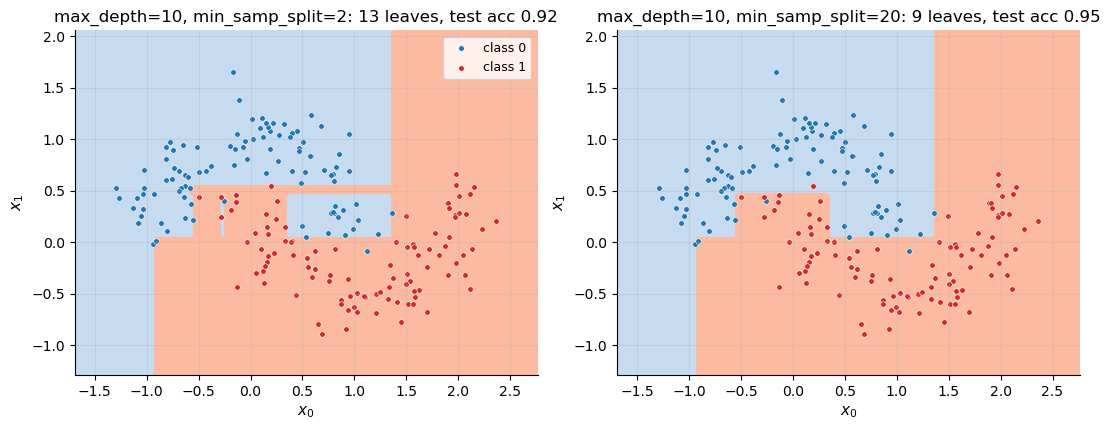

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, mss in zip(axes, [2, 20]):
    t = DecisionTreeClassifier(min_samp_split=mss, max_depth=10); t.fit(X_h, y_h.reshape(-1, 1))
    te = np.mean(np.array(t.predict(X_h_test)) == y_h_test)
    plot_decision_regions(t.predict, X_h, y_h, ax=ax, legend=(mss == 2),
                          title=f"max_depth=10, min_samp_split={mss}: {count_leaves(t.root)} leaves, test acc {te:.2f}")
plt.tight_layout(); plt.show()

With `min_samp_split = 2`, the tree builds narrow boxes around small groups of points in the overlap region. With `min_samp_split = 20`, nodes of fewer than 20 samples are never split, so those small boxes are never created. The tree keeps the large-scale shape of the two moons and scores higher on the test set (accuracies are in the panel titles).

## 9. Complexity and limitations

**Training cost.** Consider a node with $s$ samples. For each of the $m$ features there are at most $s$ candidate thresholds. For each candidate, `split` scans all $s$ rows (twice, in Python list comprehensions) and `information_gain` computes three impurities in $O(s)$ time, giving

$$
\text{cost(node)} = O(m \cdot s \cdot s) = O(m\,s^2).
$$

The nodes at one depth level partition the samples ($\sum s_i = n$), and $\sum s_i^2 \le n^2$, so one level costs at most $O(m n^2)$. A tree of depth $D$ therefore costs $O(D\,m\,n^2)$. Production CART implementations sort each feature once per node and sweep the thresholds in order, updating the class counts incrementally as one sample at a time crosses over. That makes each node $O(m\, s\log s)$ instead of $O(m\,s^2)$: an $n$-fold improvement that matters enormously for large data.

**Prediction cost.** $O(D)$ comparisons per point, independent of $n$.

**Memory.** The fitted tree stores only $O(\text{number of nodes})$ thresholds and labels. During training, `split` copies the node's data for every candidate and `build_tree` keeps the child copies alive along the recursion path, so peak memory is $O(n\,m\,D)$.

The timing experiment below measures how the fit time grows with $n$ at a fixed depth.

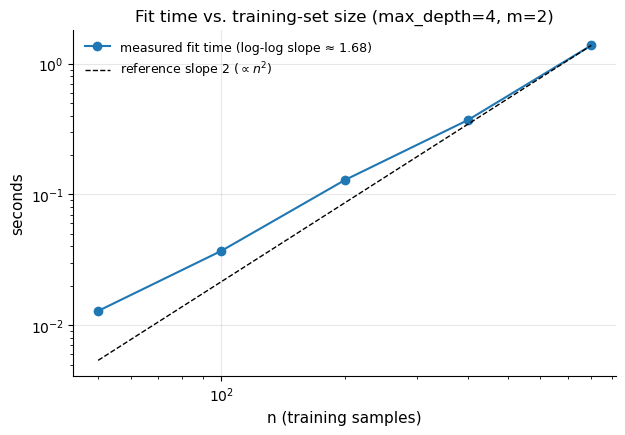

n =   50: 0.013 s
n =  100: 0.037 s
n =  200: 0.129 s
n =  400: 0.371 s
n =  800: 1.379 s
fitted log-log slope over all points: 1.68; local slope over the last doubling (400 -> 800): 1.90


In [42]:
ns, secs = [50, 100, 200, 400, 800], []
for n_ in ns:
    Xt_, yt_ = make_xor(n_, noise=0.1)
    t0 = time.perf_counter()
    DecisionTreeClassifier(min_samp_split=2, max_depth=4).fit(Xt_, yt_.reshape(-1, 1))
    secs.append(time.perf_counter() - t0)
slope = np.polyfit(np.log(ns), np.log(secs), 1)[0]

fig, ax = plt.subplots()
ax.loglog(ns, secs, "o-", label=f"measured fit time (log-log slope ≈ {slope:.2f})")
ax.loglog(ns, secs[-1] * (np.array(ns) / ns[-1]) ** 2, "k--", lw=1, label="reference slope 2 ($\\propto n^2$)")
ax.set(title="Fit time vs. training-set size (max_depth=4, m=2)", xlabel="n (training samples)", ylabel="seconds")
ax.legend(); plt.show()
for n_, s_ in zip(ns, secs):
    print(f"n = {n_:>4}: {s_:.3f} s")
print(f"fitted log-log slope over all points: {slope:.2f}; "
      f"local slope over the last doubling (400 -> 800): {np.log2(secs[-1] / secs[-2]):.2f}")

On a log-log plot, a cost proportional to $n^p$ is a straight line with slope $p$. The fitted slope is a little below 2 because, at small $n$, fixed per-call overheads (NumPy calls on tiny arrays, building `Node` objects) are a large share of the time. The local slope over the last doubling is closer to the predicted 2, and the curve steepens toward the $n^2$ reference as $n$ grows. In practice, doubling the training set multiplies the fit time by roughly 3 to 4. This is why the walkthroughs in this series use a few hundred samples. It is also why `GradientBoostRegression/Main.py`, which fits on the 20,640-row California-housing data, is very slow.

**Limitations, and how production libraries address them**

| Limitation of `DecisionTree.py` | Consequence | What e.g. scikit-learn does |
|---|---|---|
| $O(m n^2)$ per level split search (list-comprehension `split`) | slow beyond a few thousand samples | sort once per node and sweep thresholds with incremental class counts |
| Thresholds at observed values | boundaries hug training points (§4.3) | midpoints between consecutive values |
| Greedy, no look-ahead | weak first splits on XOR-like interactions (§7.3) | same greed; ensembles mitigate it |
| Only pre-pruning (`max_depth`, `min_samp_split`) | must tune depth by hand | also `min_samples_leaf`, `max_leaf_nodes`, cost-complexity pruning `ccp_alpha` |
| Leaves store only the majority class | no class probabilities | leaves store class counts; `predict_proba` |
| No sample or class weights, no missing-value handling | cannot reweight classes; NaNs unsupported | `sample_weight`, `class_weight`, native NaN support |

Bugs found during this walkthrough and **fixed in `DecisionTree.py`**:

| Original behaviour | Fix |
|---|---|
| `curr_depth <= max_depth`: trees one level deeper than requested | strict `<`; `max_depth=None` allowed (§4.4) |
| Empty `best_split` → `KeyError` on nodes of identical rows | such a node becomes a leaf (§4.4) |
| Criterion hard-coded to Gini | `criterion='gini' \| 'entropy'` constructor argument (§4.3) |
| NumPy string labels coerced the features to strings; 1-D labels rejected | labels reshaped and cast to `object` in `fit` (§5) |
| Leaf ties broken by sample order | ties go to the smallest label (§4.4) |
| `tree.value != None`, `if not tree` | identity tests `is not None` / `is None` |

A single tree's biggest practical weakness, its **high variance** (§7.2, §7.5), is not fixed by any of these refinements. It is fixed by ensembles, which the following notebooks build on top of this same tree.

## 10. Summary

- A classification tree is a **piecewise-constant** model over axis-aligned boxes (Eq. 0), learned by **recursive greedy partitioning**. It needs no feature scaling, because only the order of each feature's values matters (checked in §3).
- Node impurity is measured by **Gini** $1-\sum_k p_k^2$ (Eq. 1) or **entropy** $-\sum_k p_k\log_2 p_k$ (Eq. 2). Both are zero for pure nodes, largest for uniform mixtures, and strictly concave.
- A split is scored by its **information gain** (Eq. 3), the impurity decrease weighted by child size. Because impurity is concave and the parent's class mix is a convex combination of the children's, the gain is **never negative** (Jensen).
- `get_best_split` performs an **exhaustive search** over every feature and every distinct observed value (Eqs. 4–5), keeping the first strictly-best candidate; `build_tree` recurses until a node is small, too deep, or has no positive-gain split; leaves predict the **majority class** (Eq. 6); `predict` routes each point root-to-leaf in $O(\text{depth})$.
- The worked example (§6) reproduced every gain by hand. `fit` built exactly the hand-derived tree.
- Depth controls the **bias–variance tradeoff** (§7.1–7.2): shallow trees underfit, deep trees memorise noise, and `min_samp_split` regularises adaptively (§8). Greedy search is myopic on interaction-only problems such as XOR (§7.3), and trees are unstable under resampling (§7.5).
- Bugs found and fixed in `DecisionTree.py` during this walkthrough: trees grew one level deeper than `max_depth`; nodes of identical rows raised `KeyError`; the criterion was hard-coded to Gini; NumPy string labels turned the features into strings; leaf ties depended on sample order. Design caveats that remain: thresholds sit on training points, and training costs $O(D\,m\,n^2)$, with measured growth approaching the quadratic rate as $n$ increases.

**Next:** the same machinery with a continuous target: [Regression trees](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb).